# Interfaces and thin films

This notebook covers `pyoptics.interfaces` (Fresnel coefficients of a single
interface) and `pyoptics.thin_films` (transfer matrix calculation for layer
stacks). Topics: Brewster angle, total internal reflection with the evanescent
wave, metal reflection, soap film colours, anti-reflection coating, Bragg mirror,
thick (incoherent) plates and thin metal films.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$; absorbing media
have $\tilde n = n + i\kappa$ with $\kappa > 0$. The refracted angle is chosen such
that the transmitted wave decays away from the interface.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import interfaces as itf
from pyoptics import thin_films as tf

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})
deg = np.pi/180

## 1. Fresnel coefficients: air → glass

Different Fresnel formulas hold for s polarization (E perpendicular to the plane
of incidence) and p polarization (E in the plane of incidence). At the
**Brewster angle** $\theta_B = \arctan(n_2/n_1)$, $r_p$ vanishes: reflected and
refracted beams are perpendicular to each other, and the dipoles in the glass do
not radiate in the direction of the reflected beam. This is why light reflected
at $\theta_B$ is purely s polarized.

Energy conservation $R + T = 1$ holds with
$T = \frac{\mathrm{Re}(n_2\cos\theta_2)}{\mathrm{Re}(n_1\cos\theta_1)}|t|^2$,
not with $|t|^2$ alone.

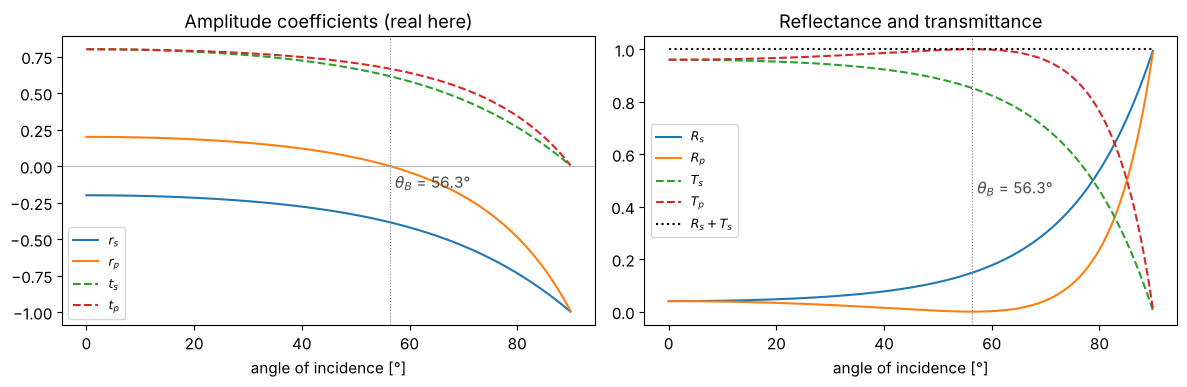

In [2]:
n1, n2 = 1.0, 1.5
theta = np.linspace(0, 89.9, 900)*deg
theta_B = itf.brewster_angle(n1, n2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(theta/deg, itf.r_s(theta, n1, n2).real, label="$r_s$")
axes[0].plot(theta/deg, itf.r_p(theta, n1, n2).real, label="$r_p$")
axes[0].plot(theta/deg, itf.t_s(theta, n1, n2).real, "--", label="$t_s$")
axes[0].plot(theta/deg, itf.t_p(theta, n1, n2).real, "--", label="$t_p$")
axes[0].axhline(0, color="0.6", lw=0.5)
axes[0].set_title("Amplitude coefficients (real here)")
axes[1].plot(theta/deg, itf.R_s(theta, n1, n2), label="$R_s$")
axes[1].plot(theta/deg, itf.R_p(theta, n1, n2), label="$R_p$")
axes[1].plot(theta/deg, itf.T_s(theta, n1, n2), "--", label="$T_s$")
axes[1].plot(theta/deg, itf.T_p(theta, n1, n2), "--", label="$T_p$")
axes[1].plot(theta/deg, itf.R_s(theta, n1, n2) + itf.T_s(theta, n1, n2), "k:", label="$R_s + T_s$")
axes[1].set_title("Reflectance and transmittance")
for ax in axes:
    ax.axvline(theta_B/deg, color="0.5", lw=0.8, ls=":")
    ax.text(theta_B/deg + 1, -0.15 if ax is axes[0] else 0.45, f"$\\theta_B$ = {theta_B/deg:.1f}°", color="0.3")
    ax.set_xlabel("angle of incidence [°]"); ax.legend(fontsize=9)
fig.tight_layout()

## 2. Glass → air: total internal reflection and the evanescent wave

Above the **critical angle** $\theta_c = \arcsin(n_2/n_1)$ everything is reflected,
$|r_s| = |r_p| = 1$. The reflection coefficients are then complex: the s and p
components pick up **different phase shifts**. Linearly polarized light thus
becomes elliptically polarized (Fresnel rhomb, see notebook 11).

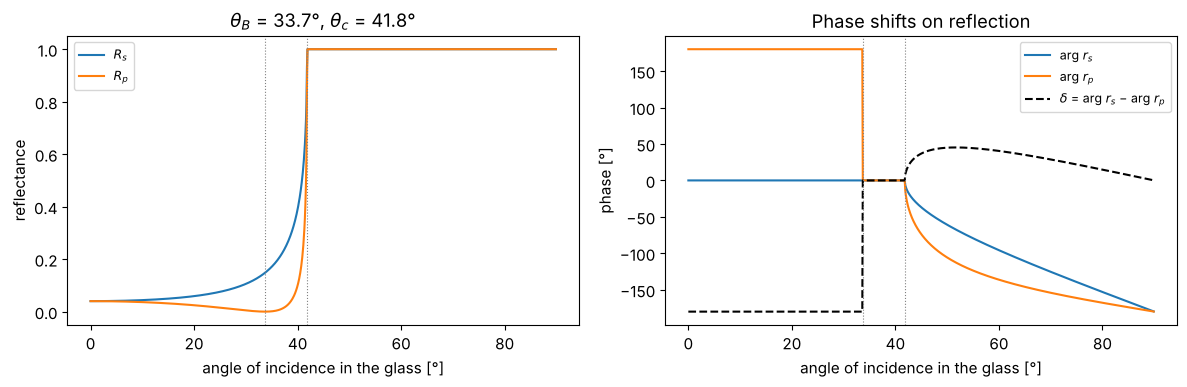

In [3]:
n1, n2 = 1.5, 1.0
theta_c = np.real(itf.critical_angle(n1, n2))
theta_B = itf.brewster_angle(n1, n2)
rs, rp = itf.r_s(theta, n1, n2), itf.r_p(theta, n1, n2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(theta/deg, np.abs(rs)**2, label="$R_s$")
axes[0].plot(theta/deg, np.abs(rp)**2, label="$R_p$")
axes[0].set_ylabel("reflectance")
axes[1].plot(theta/deg, np.angle(rs)/deg, label="arg $r_s$")
axes[1].plot(theta/deg, np.angle(rp)/deg, label="arg $r_p$")
axes[1].plot(theta/deg, (np.angle(rs) - np.angle(rp))/deg, "k--", label="$\\delta$ = arg $r_s$ − arg $r_p$")
axes[1].set_ylabel("phase [°]")
for ax in axes:
    ax.axvline(theta_c/deg, color="0.5", lw=0.8, ls=":")
    ax.axvline(theta_B/deg, color="0.5", lw=0.8, ls=":")
    ax.set_xlabel("angle of incidence in the glass [°]"); ax.legend(fontsize=9)
axes[0].set_title(f"$\\theta_B$ = {theta_B/deg:.1f}°, $\\theta_c$ = {theta_c/deg:.1f}°")
axes[1].set_title("Phase shifts on reflection")
fig.tight_layout()

What does the field at the interface look like? For s polarization, $E_y$ in the
glass ($z<0$) is the sum of the incident and reflected waves, in the air ($z>0$)
it is the transmitted wave

$$E_y = t_s\, e^{i(k_x x + k_{z,2} z)}, \qquad k_{z,2} = n_2 k_0 \cos\theta_2 .$$

Under total internal reflection, $\cos\theta_2$ (from `refracted_angle()`) is
purely imaginary with a positive imaginary part: the wave runs along the
interface and decays exponentially in $z$, with the penetration depth
$d = 1/\mathrm{Im}\,k_{z,2} = \lambda/(2\pi\sqrt{n_1^2\sin^2\theta - n_2^2})$.
Shown is a snapshot $\mathrm{Re}\,E_y$.

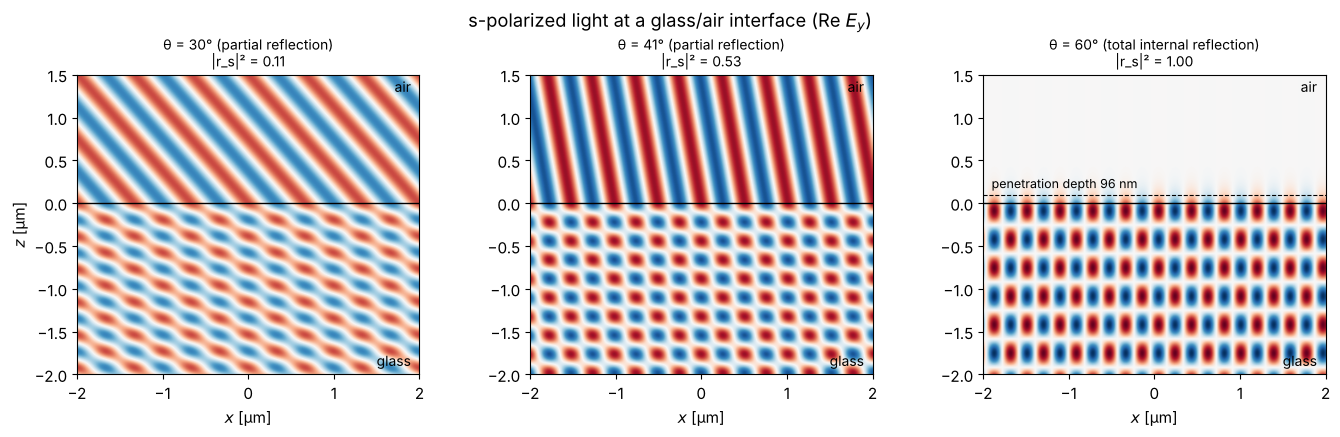

In [4]:
wl = 0.5
k0 = 2*np.pi/wl
xg = np.linspace(-2, 2, 400)
zg = np.linspace(-2, 1.5, 350)
Xg, Zg = np.meshgrid(xg, zg)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, th_deg in zip(axes, (30, 41, 60)):
    th = th_deg*deg
    th2 = itf.refracted_angle(th, n1, n2)
    kx = n1*k0*np.sin(th)
    kz1 = n1*k0*np.cos(th)
    kz2 = n2*k0*np.cos(th2)
    r, t = itf.r_s(th, n1, n2), itf.t_s(th, n1, n2)
    E = np.where(Zg < 0,
                 np.exp(1j*(kx*Xg + kz1*Zg)) + r*np.exp(1j*(kx*Xg - kz1*Zg)),
                 t*np.exp(1j*(kx*Xg + kz2*Zg)))
    ax.imshow(np.real(E), extent=(xg[0], xg[-1], zg[0], zg[-1]), cmap="RdBu_r", vmin=-2, vmax=2)
    ax.axhline(0, color="k", lw=1)
    label = "total internal reflection" if th > theta_c else "partial reflection"
    ax.set_title(f"θ = {th_deg}° ({label})\n|r_s|² = {abs(r)**2:.2f}", fontsize=10)
    ax.set_xlabel("$x$ [µm]")
    if th > theta_c:
        d = 1/np.imag(kz2)
        ax.axhline(d, color="k", ls="--", lw=0.8)
        ax.text(-1.9, d + 0.08, f"penetration depth {1000*d:.0f} nm", fontsize=9)
    ax.text(1.9, -1.9, "glass", ha="right", fontsize=10); ax.text(1.9, 1.3, "air", ha="right", fontsize=10)
axes[0].set_ylabel("$z$ [µm]")
fig.suptitle("s-polarized light at a glass/air interface (Re $E_y$)")
fig.tight_layout()

## 3. Reflection at metals

Metals have a large imaginary part of the refractive index. $R_p$ then no longer
has a true zero, but a minimum at the *principal angle* (pseudo-Brewster angle).
Ellipsometry uses the phase difference $\delta = \arg r_s - \arg r_p$ to determine
$n$ and $\kappa$: it falls from $180°$ (normal incidence, where $r_p = -r_s$ in the
Hecht convention) to $0°$ (grazing incidence) and is exactly $90°$ at the principal
angle (dots). For glass, in contrast, it jumps from $180°$ to $0°$ at the Brewster
angle.

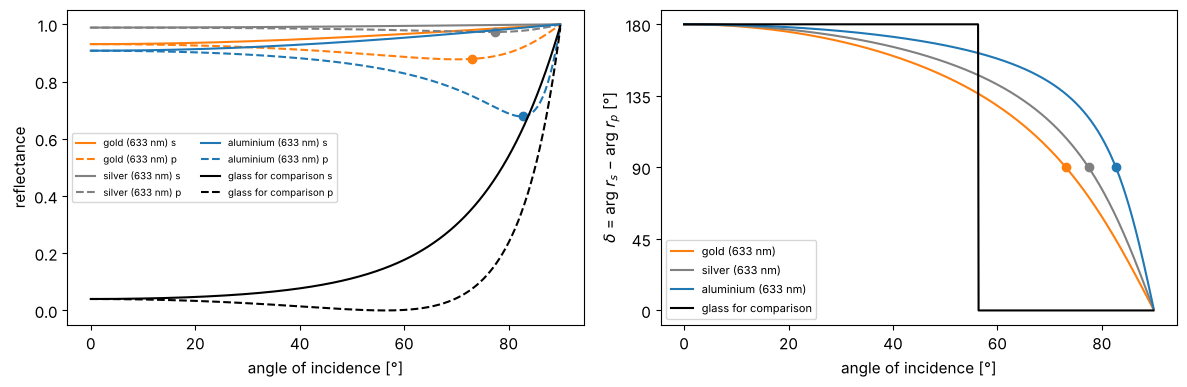

In [5]:
metals = {"gold (633 nm)": 0.18 + 3.0j, "silver (633 nm)": 0.056 + 4.28j, "aluminium (633 nm)": 1.45 + 7.54j,
          "glass for comparison": 1.5 + 0j}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (name, nm), c in zip(metals.items(), ("C1", "0.5", "C0", "k")):
    axes[0].plot(theta/deg, itf.R_s(theta, 1.0, nm), color=c, ls="-", label=name + " s")
    axes[0].plot(theta/deg, itf.R_p(theta, 1.0, nm), color=c, ls="--", label=name + " p")
    delta = np.mod((np.angle(itf.r_s(theta, 1.0, nm)) - np.angle(itf.r_p(theta, 1.0, nm)))/deg + 1e-9, 360)
    axes[1].plot(theta/deg, delta, color=c, label=name)
    if nm.imag > 0:
        i90 = np.argmin(np.abs(delta - 90))
        axes[1].plot(theta[i90]/deg, 90, "o", color=c)
        axes[0].plot(theta[i90]/deg, itf.R_p(theta[i90], 1.0, nm), "o", color=c)
axes[0].set_ylabel("reflectance"); axes[0].legend(fontsize=7, ncol=2)
axes[1].set_ylabel("$\\delta$ = arg $r_s$ − arg $r_p$ [°]"); axes[1].legend(fontsize=8)
axes[1].set_yticks([0, 45, 90, 135, 180])
for ax in axes:
    ax.set_xlabel("angle of incidence [°]")
fig.tight_layout()

## 4. Thin films: the transfer matrix

`thin_films.r_t_coeffs()` computes the amplitude coefficients of a layer stack
(Zangwill/McLeod), `R_T_A_coeffs()` the intensities and the absorption
$A = 1 - R - T$. As a check: a layer of zero thickness must give the bare interface.

Note: `thin_films` refers $r$ and $t$ to the **tangential** field components. For p
polarization, the sign of $r_p$ therefore differs from the Hecht convention used
in `interfaces`; the intensities are the same.

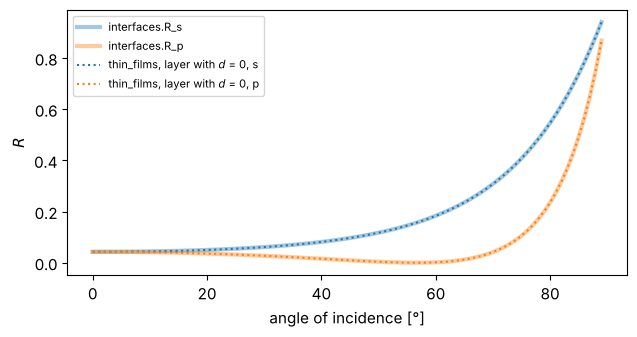

In [6]:
def stack_RTA(theta, wl, n, k, t, n_emb=1.0, n_sub=1.52, k_sub=0.0, pol="s", **kw):
    return tf.R_T_A_coeffs(theta, n, k, t, n_emb, 0.0, n_sub, k_sub, pol, wl, **kw)

th = np.linspace(0, 89, 90)*deg
R_stack = {pol: [stack_RTA(a, 0.55, [1.38], [0.0], [0.0], pol=pol)[0] for a in th] for pol in "sp"}
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(th/deg, itf.R_s(th, 1.0, 1.52), "C0", lw=3, alpha=0.4, label="interfaces.R_s")
ax.plot(th/deg, itf.R_p(th, 1.0, 1.52), "C1", lw=3, alpha=0.4, label="interfaces.R_p")
ax.plot(th/deg, R_stack["s"], "C0:", label="thin_films, layer with $d$ = 0, s")
ax.plot(th/deg, R_stack["p"], "C1:", label="thin_films, layer with $d$ = 0, p")
ax.set_xlabel("angle of incidence [°]"); ax.set_ylabel("$R$"); ax.legend(fontsize=8)
fig.tight_layout()

### 4.1 Colours of a soap film

A water film ($n = 1.33$) in air preferentially reflects different wavelengths
depending on its thickness. We compute $R(\lambda)$ at normal incidence and convert
the spectrum into sRGB colours with the CIE 1931 colour matching functions
(analytic approximation by Wyman, Sloan and Shirley). Illumination: equal-energy
white; the brightness is boosted for better visibility.

Very thin films appear **black**: the reflection at the front surface
(low → high index) has a phase jump of $\pi$ relative to the one at the back
surface, so for $d \to 0$ the two contributions cancel. With increasing thickness
come white, yellow, purple, blue, ... (Newton's colour sequence), until the colours
fade at a few µm because the interference maxima of many orders overlap in the
visible spectrum.

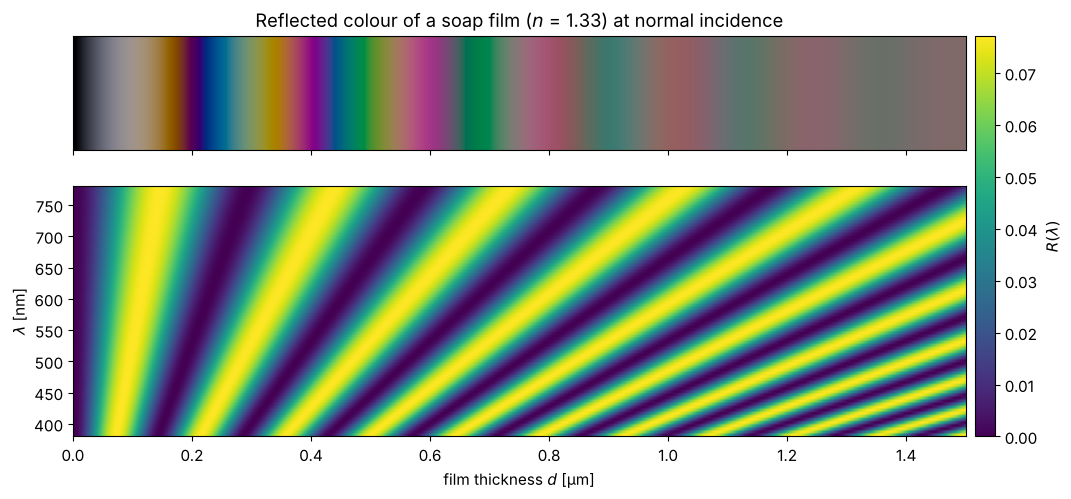

In [7]:
def _g(lam, mu, s1, s2):
    s = np.where(lam < mu, s1, s2)
    return np.exp(-0.5*(lam - mu)**2/s**2)

def cie_xyz(lam_nm):
    xb = 1.056*_g(lam_nm, 599.8, 37.9, 31.0) + 0.362*_g(lam_nm, 442.0, 16.0, 26.7) - 0.065*_g(lam_nm, 501.1, 20.4, 26.2)
    yb = 0.821*_g(lam_nm, 568.8, 46.9, 40.5) + 0.286*_g(lam_nm, 530.9, 16.3, 31.1)
    zb = 1.217*_g(lam_nm, 437.0, 11.8, 36.0) + 0.681*_g(lam_nm, 459.0, 26.0, 13.8)
    return np.array([xb, yb, zb])

M_XYZ_to_sRGB = np.array([[3.2406, -1.5372, -0.4986], [-0.9689, 1.8758, 0.0415], [0.0557, -0.2040, 1.0570]])

def spectrum_to_rgb(lam_nm, S, gain=1.0):
    cmf = cie_xyz(lam_nm)
    XYZ = cmf @ S/np.sum(cmf[1])     # S = 1 everywhere -> Y = 1 (white)
    rgb = np.clip(gain*(M_XYZ_to_sRGB @ XYZ), 0, 1)
    return np.where(rgb <= 0.0031308, 12.92*rgb, 1.055*rgb**(1/2.4) - 0.055)  # sRGB gamma

lam = np.linspace(380, 780, 81)
d_vals = np.linspace(0, 1.5, 451)  # thickness in µm
R_map = np.array([[stack_RTA(0.0, l/1000, [1.33], [0.0], [d], n_sub=1.0)[0] for l in lam] for d in d_vals])
colors = np.array([spectrum_to_rgb(lam, R, gain=4.0) for R in R_map])

fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), gridspec_kw={"height_ratios": [1, 2.2]}, sharex=True)
axes[0].imshow(colors[np.newaxis, :, :], extent=(d_vals[0], d_vals[-1], 0, 1), aspect="auto")
axes[0].set_yticks([]); axes[0].set_title("Reflected colour of a soap film ($n$ = 1.33) at normal incidence")
im = axes[1].imshow(R_map.T, extent=(d_vals[0], d_vals[-1], lam[0], lam[-1]), aspect="auto", cmap="viridis")
axes[1].set_xlabel("film thickness $d$ [µm]"); axes[1].set_ylabel("$\\lambda$ [nm]")
fig.colorbar(im, ax=axes, label="$R(\\lambda)$", fraction=0.03, pad=0.01)

### 4.2 Anti-reflection coating

A layer of optical thickness $\lambda_0/4$ makes the reflections at its front and
back surfaces interfere with a phase difference of $\pi$. They cancel completely
when both are equally strong, i.e. for $n_\text{layer} = \sqrt{n_\text{glass}}$.
Real MgF$_2$ ($n = 1.38$) comes close enough to reduce the reflection from 4.3 % to
about 1.3 %.

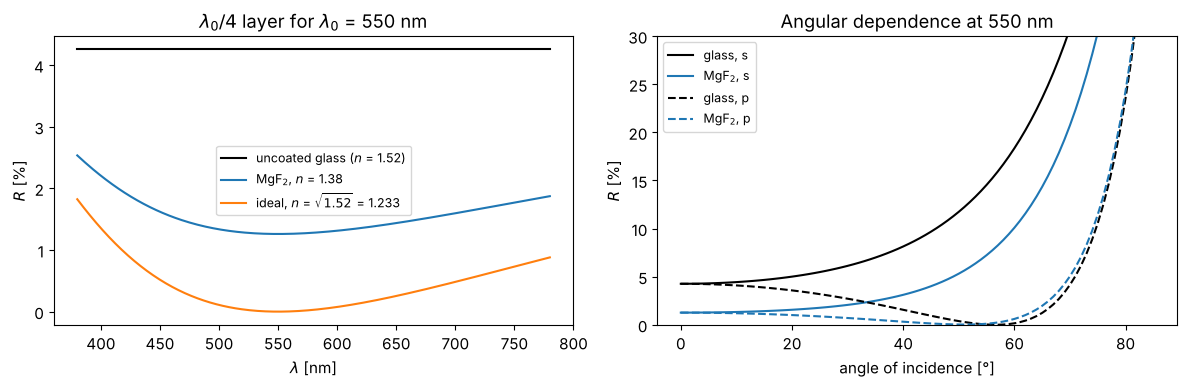

In [8]:
lam = np.linspace(0.38, 0.78, 300)
lam0 = 0.55
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
R_bare = [stack_RTA(0.0, l, [1.0], [0.0], [0.0])[0] for l in lam]
axes[0].plot(lam*1000, np.array(R_bare)*100, "k", label="uncoated glass ($n$ = 1.52)")
for n_c, lab in ((1.38, "MgF$_2$, $n$ = 1.38"), (np.sqrt(1.52), f"ideal, $n$ = $\\sqrt{{1.52}}$ = {np.sqrt(1.52):.3f}")):
    R = [stack_RTA(0.0, l, [n_c], [0.0], [lam0/(4*n_c)])[0] for l in lam]
    axes[0].plot(lam*1000, np.array(R)*100, label=lab)
axes[0].set_xlabel("$\\lambda$ [nm]"); axes[0].set_ylabel("$R$ [%]"); axes[0].legend(fontsize=9)
axes[0].set_title(f"$\\lambda_0/4$ layer for $\\lambda_0$ = {lam0*1000:.0f} nm")

th = np.linspace(0, 85, 86)*deg
for pol, ls in (("s", "-"), ("p", "--")):
    axes[1].plot(th/deg, [100*stack_RTA(a, lam0, [1.0], [0.0], [0.0], pol=pol)[0] for a in th], "k" + ls, label=f"glass, {pol}")
    axes[1].plot(th/deg, [100*stack_RTA(a, lam0, [1.38], [0.0], [lam0/(4*1.38)], pol=pol)[0] for a in th], "C0" + ls, label=f"MgF$_2$, {pol}")
axes[1].set_ylim(0, 30); axes[1].set_xlabel("angle of incidence [°]"); axes[1].set_ylabel("$R$ [%]")
axes[1].legend(fontsize=9); axes[1].set_title(f"Angular dependence at {lam0*1000:.0f} nm")
fig.tight_layout()

### 4.3 Bragg mirror

Alternating $\lambda_0/4$ layers of high and low index material (TiO$_2$/SiO$_2$)
reflect almost completely in a **stop band** around $\lambda_0$. The reflectance
grows with the number of pairs; the width of the stop band depends only on the
index contrast. In frequency, it is symmetric about $\omega_0$ with the relative
width

$$\frac{\Delta\omega}{\omega_0} = \frac{4}{\pi}\arcsin\frac{n_H - n_L}{n_H + n_L},$$

so in wavelength it is asymmetric, with edges at
$\lambda_0/(1 \pm \Delta\omega/2\omega_0)$.

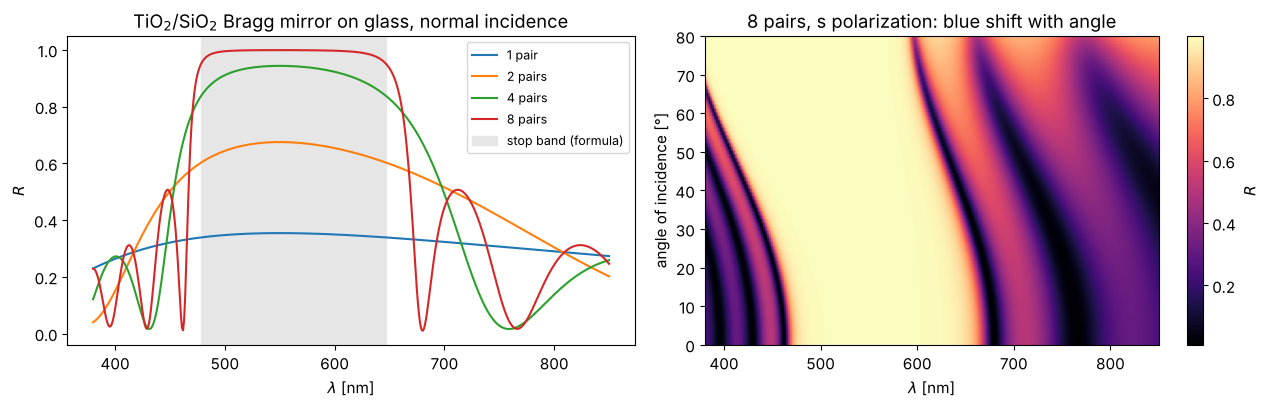

In [9]:
nH, nL = 2.35, 1.46
lam0 = 0.55
def bragg(N_pairs):
    n = [nH, nL]*N_pairs
    t = [lam0/(4*nH), lam0/(4*nL)]*N_pairs
    return n, [0.0]*len(n), t

lam = np.linspace(0.38, 0.85, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for N_pairs in (1, 2, 4, 8):
    n, k, t = bragg(N_pairs)
    axes[0].plot(lam*1000, [stack_RTA(0.0, l, n, k, t)[0] for l in lam], label=f"{N_pairs} pair" + ("s" if N_pairs > 1 else ""))
dw = 4/np.pi*np.arcsin((nH - nL)/(nH + nL))
axes[0].axvspan(lam0/(1 + dw/2)*1000, lam0/(1 - dw/2)*1000, color="0.9", zorder=-1, label="stop band (formula)")
axes[0].set_xlabel("$\\lambda$ [nm]"); axes[0].set_ylabel("$R$"); axes[0].legend(fontsize=9)
axes[0].set_title("TiO$_2$/SiO$_2$ Bragg mirror on glass, normal incidence")

n, k, t = bragg(8)
th = np.linspace(0, 80, 81)*deg
lam_map = np.linspace(0.38, 0.85, 240)
R_s = np.array([[stack_RTA(a, l, n, k, t, pol="s")[0] for l in lam_map] for a in th])
im = axes[1].imshow(R_s, extent=(lam_map[0]*1000, lam_map[-1]*1000, 0, 80), aspect="auto", cmap="magma")
axes[1].set_xlabel("$\\lambda$ [nm]"); axes[1].set_ylabel("angle of incidence [°]")
axes[1].set_title("8 pairs, s polarization: blue shift with angle")
fig.colorbar(im, ax=axes[1], label="$R$")
fig.tight_layout()

At oblique incidence the phase in each layer becomes $k_0 n d\cos\theta$, the
effective optical thickness decreases and the stop band moves to shorter
wavelengths. This is behind the play of colours of many butterfly wings and
beetle shells.

### 4.4 Thick plates: coherent or incoherent?

Strictly speaking, a 1 mm thick glass plate is a Fabry-Pérot resonator. But the
interference fringes are so dense ($\Delta\lambda = \lambda^2/(2nd) \approx 0.1$ nm)
that every real spectrometer and every real light source averages them out.
`R_T_A_coeffs(..., incoherent=[True], N_phases=...)` averages the intensities over
the phase in the layer. The result is the sum of the reflections without
interference, $R = 2R_1/(1 + R_1)$.

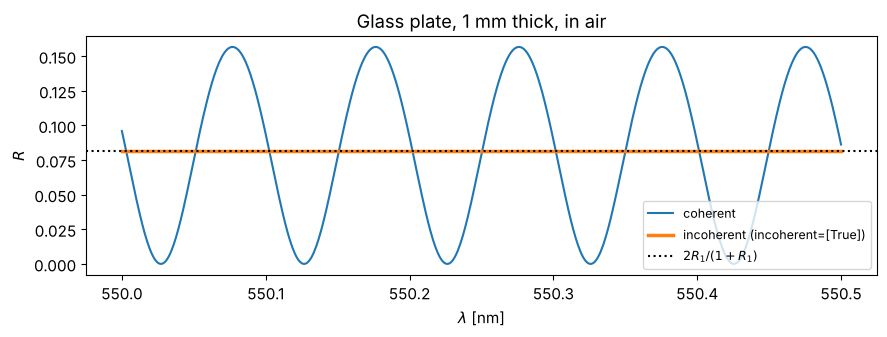

In [10]:
lam = np.linspace(0.5500, 0.5505, 600)
d = 1000.0
R_coh = [stack_RTA(0.0, l, [1.52], [0.0], [d], n_sub=1.0)[0] for l in lam]
R_inc = [stack_RTA(0.0, l, [1.52], [0.0], [d], n_sub=1.0, incoherent=[True], N_phases=64)[0] for l in lam]
R1 = ((1.52 - 1)/(1.52 + 1))**2
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lam*1000, R_coh, label="coherent")
ax.plot(lam*1000, R_inc, lw=2.5, label="incoherent (incoherent=[True])")
ax.axhline(2*R1/(1 + R1), color="k", ls=":", label="$2R_1/(1+R_1)$")
ax.set_xlabel("$\\lambda$ [nm]"); ax.set_ylabel("$R$"); ax.legend(fontsize=9)
ax.set_title("Glass plate, 1 mm thick, in air")
fig.tight_layout()

### 4.5 Thin metal films: reflection, transmission, absorption

A silver film becomes a mirror after just a few tens of nm and absorbs hardly any
light in the process (silver has a very small real part $n$). Chromium
($n \approx 3.1 + 3.3i$), on the other hand, absorbs strongly: from about 10 nm on,
a chromium film swallows some 40 % of the light. Such films serve as neutral
density filters.

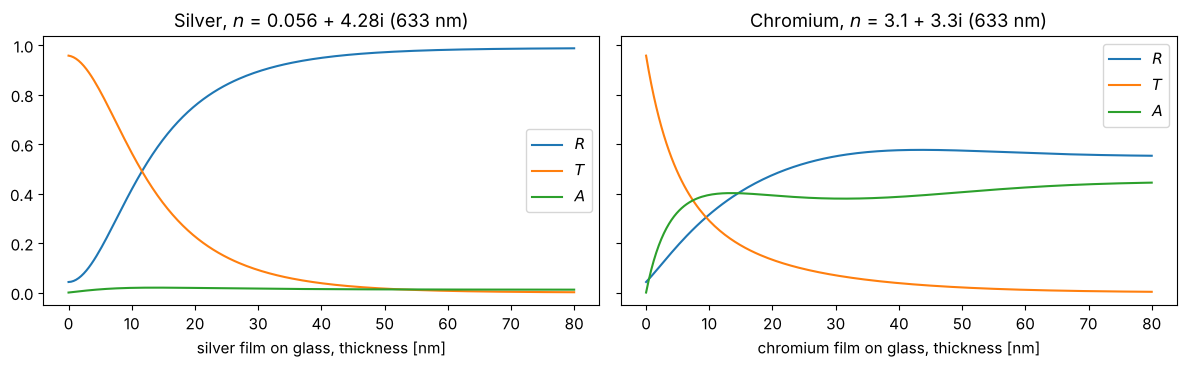

In [11]:
d_vals = np.linspace(0, 0.08, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, n_m) in zip(axes, (("silver", 0.056 + 4.28j), ("chromium", 3.1 + 3.3j))):
    RTA = np.array([stack_RTA(0.0, 0.633, [n_m.real], [n_m.imag], [d]) for d in d_vals])
    for i, lab in enumerate(("$R$", "$T$", "$A$")):
        ax.plot(d_vals*1000, RTA[:, i], label=lab)
    ax.set_xlabel(f"{name} film on glass, thickness [nm]"); ax.legend()
    ax.set_title(f"{name.capitalize()}, $n$ = {n_m.real} + {n_m.imag}i (633 nm)")
fig.tight_layout()